<a href="https://colab.research.google.com/github/kavy988/ai-ml-dl-learning/blob/main/machine-learning/ch07_Dimensionality_Reduction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Dimensionality Reduction

* Reducing dimensionality can also drop some useful information , just like compressing an image to JPEG can degrade its quality .

* Adding an extra preprocessing step for dimensionality reduction will not always help .



## 0.Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sklearn

from pathlib import Path

In [2]:
IMAGES_PATH = Path() / "images" / "dim_reduction"
IMAGES_PATH.mkdir(parents = True, exist_ok = True)

## 1.Curse of Dimensionality

- We are so used to living in three dimensions⁠
that our intuition fails us when we try to imagine a high-dimensional space.
Even a basic 4D hypercube is incredibly hard to picture in our minds, let alone a 200-dimensional
ellipsoid bent in a 1,000-dimensional space.

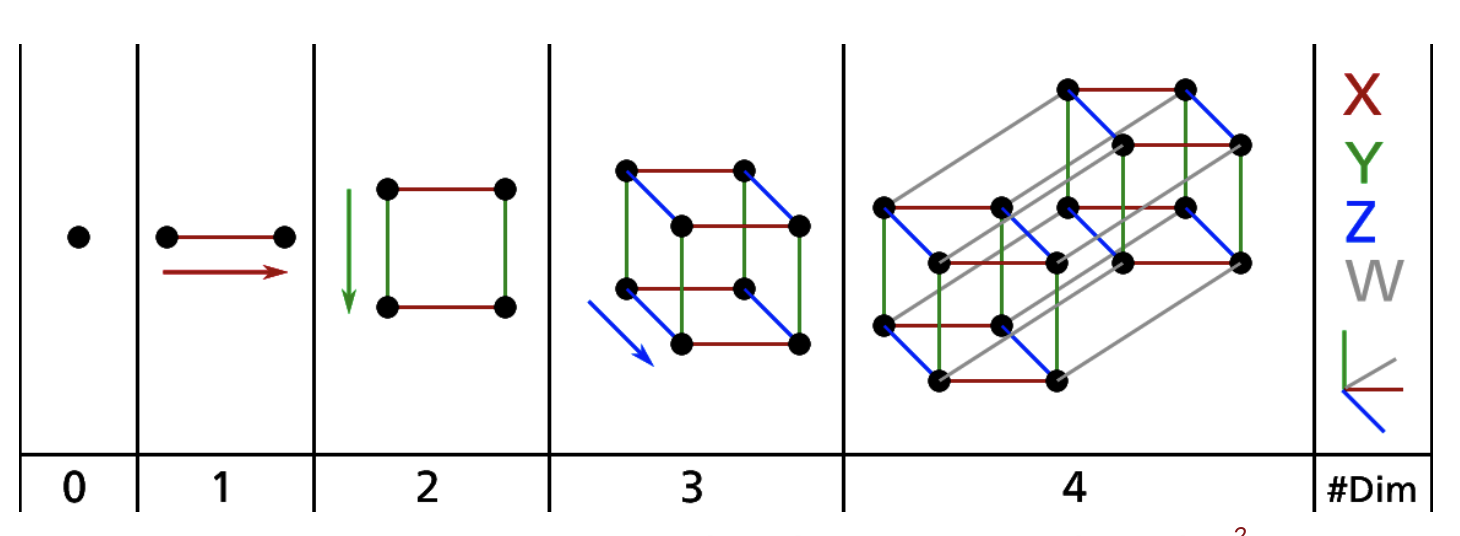

Point, segment, square, cube, and tesseract (0D to 4D hypercubes)

---



Note:-

If we want to locate a point randomly then ,
most points in a high-dimensional hypercube are very close
to the border.

Moreover,

if you pick two points randomly in a unit square, the distance between these two
points will be, on average, roughly 0.52. If you pick two random points in a 3D unit cube, the average distance will be
roughly 0.66.

But

what about two points picked randomly in a 1,000,000-dimensional unit hypercube? The average
distance, believe it or not, will be about 408.25 (roughly
$√1.000000 / 6 )$!


Because there is planty of space in high dimensions

CONCLUSION

- The high-dimensional datasets are often very small in quantity :

most training instances are likely to be far away from each
other, so training methods based on distance or similarity (such as k-nearest neighbors) will be much less effective.

Also


some types of models will not be usable at all because they scale poorly with the dataset’s dimensionality (e.g., SVMs or
dense neural networks).



---



### 1.1 Main approaches for Dimensionality Reduction

Approaches :-  

1. Projection
2. Mainfold Learning



### 1.2 Projection

In real world mostly , training instances aren't uniformly spreaded , Features(many) -> Correlated , also Almost contant And all training instanced lie within a lower-dimensional subspace of the high dimensional space.



In [3]:
# Extra
import numpy as np
from scipy.spatial.transform import Rotation

m = 60 # no. of instances
X = np.zeros((m,3)) # 3D dataset

np.random.seed(42)
angles = (np.random.rand(m) ** 3 + 0.5) * 2 * np.pi # uneven distribution

X[:,0] , X[:,1] = np.cos(angles) , np.sin(angles) * 0.5 # oval

X += 0.28 * np.random.randn(m,3) # add more noise
X = Rotation.from_rotvec([np.pi / 29 , np.pi / 20, np.pi / 4]).apply(X)
X += [0.2 , 0, 0.2] # shift a bit

Below here is a 3D dataset , represented by small spheres.

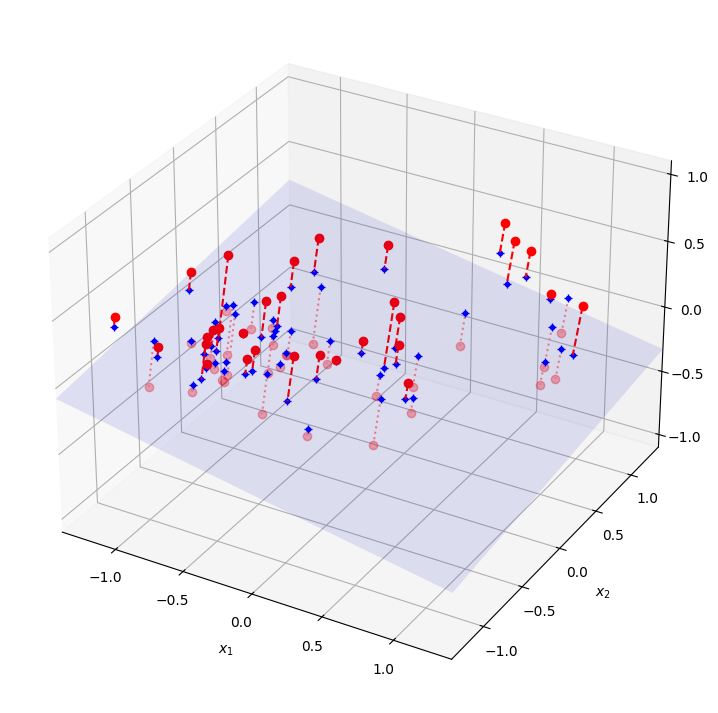

In [4]:
# extra code – this cell generates and saves Figure 8–2

import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X2D = pca.fit_transform(X)  # dataset reduced to 2D
X3D_inv = pca.inverse_transform(X2D)  # 3D position of the projected samples
X_centered = X - X.mean(axis=0)
U, s, Vt = np.linalg.svd(X_centered)

axes = [-1.4, 1.4, -1.4, 1.4, -1.1, 1.1]
x1, x2 = np.meshgrid(np.linspace(axes[0], axes[1], 10),
                     np.linspace(axes[2], axes[3], 10))
w1, w2 = np.linalg.solve(Vt[:2, :2], Vt[:2, 2])  # projection plane coefs
z = w1 * (x1 - pca.mean_[0]) + w2 * (x2 - pca.mean_[1]) - pca.mean_[2]  # plane
X3D_above = X[X[:, 2] >= X3D_inv[:, 2]]  # samples above plane
X3D_below = X[X[:, 2] < X3D_inv[:, 2]]  # samples below plane

fig = plt.figure(figsize=(9, 9))
ax = fig.add_subplot(111, projection="3d")

# plot samples and projection lines below plane first
ax.plot(X3D_below[:, 0], X3D_below[:, 1], X3D_below[:, 2], "ro", alpha=0.3)
for i in range(m):
    if X[i, 2] < X3D_inv[i, 2]:
        ax.plot([X[i][0], X3D_inv[i][0]],
                [X[i][1], X3D_inv[i][1]],
                [X[i][2], X3D_inv[i][2]], ":", color="#F88")

ax.plot_surface(x1, x2, z, alpha=0.1, color="b")  # projection plane
ax.plot(X3D_inv[:, 0], X3D_inv[:, 1], X3D_inv[:, 2], "b+")  # projected samples
ax.plot(X3D_inv[:, 0], X3D_inv[:, 1], X3D_inv[:, 2], "b.")

# now plot projection lines and samples above plane
for i in range(m):
    if X[i, 2] >= X3D_inv[i, 2]:
        ax.plot([X[i][0], X3D_inv[i][0]],
                [X[i][1], X3D_inv[i][1]],
                [X[i][2], X3D_inv[i][2]], "r--")

ax.plot(X3D_above[:, 0], X3D_above[:, 1], X3D_above[:, 2], "ro")

def set_xyz_axes(ax, axes):
    ax.xaxis.set_rotate_label(False)
    ax.yaxis.set_rotate_label(False)
    ax.zaxis.set_rotate_label(False)
    ax.set_xlabel("$x_1$", labelpad=8, rotation=0)
    ax.set_ylabel("$x_2$", labelpad=8, rotation=0)
    ax.set_zlabel("$x_3$", labelpad=8, rotation=0)
    ax.set_xlim(axes[0:2])
    ax.set_ylim(axes[2:4])
    ax.set_zlim(axes[4:6])

set_xyz_axes(ax, axes)
ax.set_zticks([-1, -0.5, 0, 0.5, 1])
plt.show()

Here all training instances lie close to plane , which is a lower dimensional(2D) subspace of the high(3D) dimensional space.


If we project every training instance perpendicularly onto this subspace (as represented by the short dashed
lines connecting the instances to the plane), we get the new 2D dataset

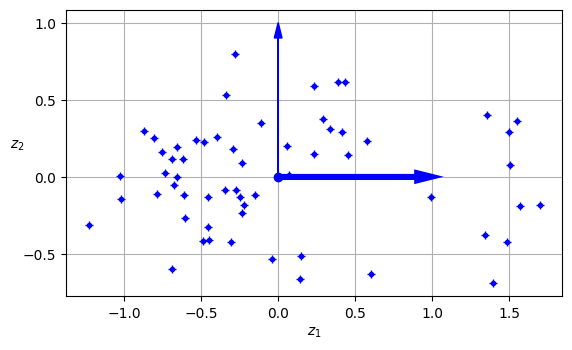

In [5]:
# extra
# 2D dataset
fig = plt.figure()
ax = fig.add_subplot(1, 1, 1, aspect='equal')
ax.plot(X2D[:, 0], X2D[:, 1], "b+")
ax.plot(X2D[:, 0], X2D[:, 1], "b.")
ax.plot([0], [0], "bo")
ax.arrow(0, 0, 1, 0, head_width=0.05, length_includes_head=True,
         head_length=0.1, fc='b', ec='b', linewidth=4)
ax.arrow(0, 0, 0, 1, head_width=0.05, length_includes_head=True,
         head_length=0.1, fc='b', ec='b', linewidth=1)
ax.set_xlabel("$z_1$")
ax.set_yticks([-0.5, 0, 0.5, 1])
ax.set_ylabel("$z_2$", rotation=0)
ax.set_axisbelow(True)
ax.grid(True)
plt.show()

the axes correspond to new features z1 and z2: they are the
coordinates of the projections on the plane.



---



### 1.3 Mainfold Learning

Although projection is fast and often works well, it’s not always the best approach to dimensionality reduction. In many
cases the subspace may twist and turn, such as in the Swiss roll dataset  this is a toy dataset
containing 3D points in the shape of a Swiss roll

In [6]:
from sklearn.datasets import make_swiss_roll

X_swiss , t = make_swiss_roll(n_samples = 1000 , noise = 0.2, random_state = 42)


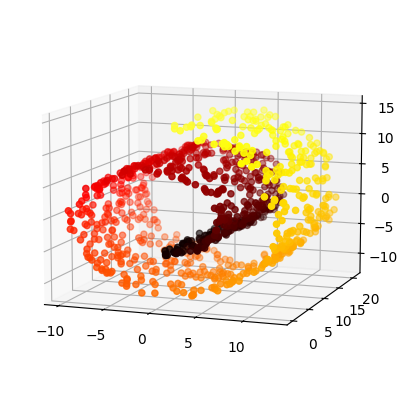

In [7]:
# extra , plotting the swiss_roll dataset

from matplotlib.colors import ListedColormap

darker_hot = ListedColormap(plt.cm.hot(np.linspace(0, 0.8, 256)))

axes = [-11.5, 14, -2, 23, -12, 15]

fig = plt.figure(figsize=(6, 5))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(X_swiss[:, 0], X_swiss[:, 1], X_swiss[:, 2], c=t, cmap=darker_hot)
ax.view_init(10, -70)
plt.show()

Now , Simply projecting onto a plane (e.g., by dropping x3) would squash different layers of the Swiss roll together, as shown on the left side

But What you probably want instead is to unroll the Swiss roll to obtain the 2D dataset , shown on the righthand side

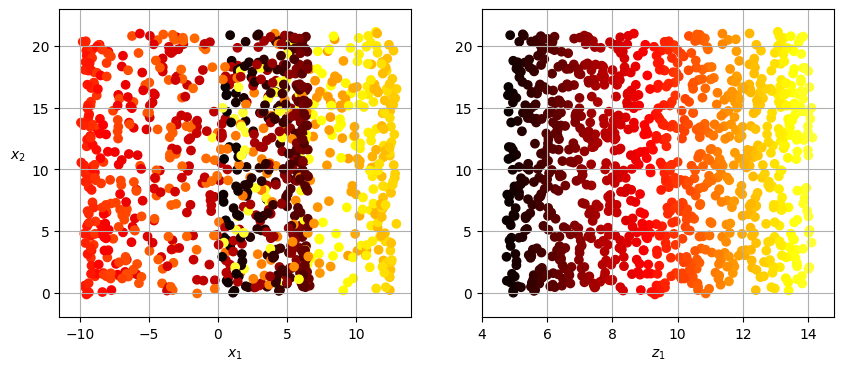

In [8]:
# Extra
plt.figure(figsize=(10, 4))

plt.subplot(121)
plt.scatter(X_swiss[:, 0], X_swiss[:, 1], c=t, cmap=darker_hot)
plt.axis(axes[:4])
plt.xlabel("$x_1$")
plt.ylabel("$x_2$", labelpad=10, rotation=0)
plt.grid(True)

plt.subplot(122)
plt.scatter(t, X_swiss[:, 1], c=t, cmap=darker_hot)
plt.axis([4, 14.8, axes[2], axes[3]])
plt.xlabel("$z_1$")
plt.grid(True)
plt.show()

The Swiss roll is an example of a 2D manifold. Put simply, a 2D manifold is a 2D shape that can be bent and twisted in a
higher-dimensional space. More generally, a d-dimensional manifold is a part of an n-dimensional space (where d < n)
that locally resembles a d-dimensional hyperplane. In the case of the Swiss roll, d = 2 and n = 3: it locally resembles a 2D
plane, but it is rolled in the third dimension.

Some Dimensionality reduction algorithms :  
- LLE, Isomap, t-SNE, or UMAP

These algos work by modeling the mainfold on which the training instances lie , this is called mainfold learning , relies on the mainfold assumption called the mainfold hypothesis , holding the most real world high dimnesional datasets .



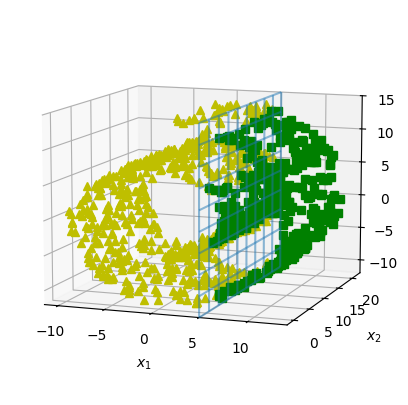

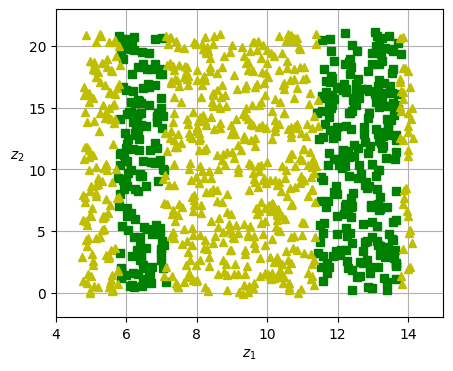

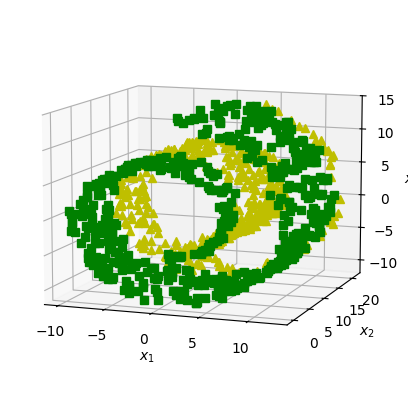

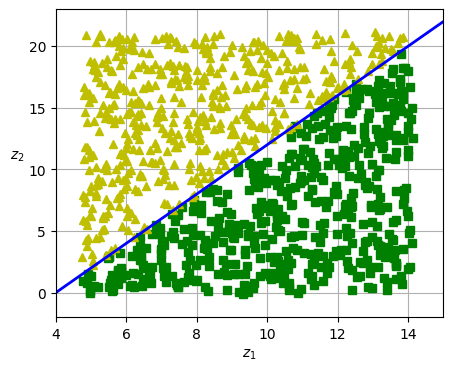

In [9]:
# extra code
axes = [-11.5, 14, -2, 23, -12, 15]
x2s = np.linspace(axes[2], axes[3], 10)
x3s = np.linspace(axes[4], axes[5], 10)
x2, x3 = np.meshgrid(x2s, x3s)

positive_class = X_swiss[:, 0] > 5
X_pos = X_swiss[positive_class]
X_neg = X_swiss[~positive_class]

fig = plt.figure(figsize=(6, 5))
ax = plt.subplot(1, 1, 1, projection='3d')
ax.view_init(10, -70)
ax.plot(X_neg[:, 0], X_neg[:, 1], X_neg[:, 2], "y^")
ax.plot_wireframe(5, x2, x3, alpha=0.5)
ax.plot(X_pos[:, 0], X_pos[:, 1], X_pos[:, 2], "gs")
set_xyz_axes(ax, axes)
plt.show()

fig = plt.figure(figsize=(5, 4))
ax = plt.subplot(1, 1, 1)
ax.plot(t[positive_class], X_swiss[positive_class, 1], "gs")
ax.plot(t[~positive_class], X_swiss[~positive_class, 1], "y^")
ax.axis([4, 15, axes[2], axes[3]])
ax.set_xlabel("$z_1$")
ax.set_ylabel("$z_2$", rotation=0, labelpad=8)
ax.grid(True)
plt.show()

positive_class = 2 * (t[:] - 4) > X_swiss[:, 1]
X_pos = X_swiss[positive_class]
X_neg = X_swiss[~positive_class]

fig = plt.figure(figsize=(6, 5))
ax = plt.subplot(1, 1, 1, projection='3d')
ax.view_init(10, -70)
ax.plot(X_neg[:, 0], X_neg[:, 1], X_neg[:, 2], "y^")
ax.plot(X_pos[:, 0], X_pos[:, 1], X_pos[:, 2], "gs")
ax.xaxis.set_rotate_label(False)
ax.yaxis.set_rotate_label(False)
ax.zaxis.set_rotate_label(False)
ax.set_xlabel("$x_1$", rotation=0)
ax.set_ylabel("$x_2$", rotation=0)
ax.set_zlabel("$x_3$", rotation=0)
ax.set_xlim(axes[0:2])
ax.set_ylim(axes[2:4])
ax.set_zlim(axes[4:6])
plt.show()

fig = plt.figure(figsize=(5, 4))
ax = plt.subplot(1, 1, 1)
ax.plot(t[positive_class], X_swiss[positive_class, 1], "gs")
ax.plot(t[~positive_class], X_swiss[~positive_class, 1], "y^")
ax.plot([4, 15], [0, 22], "b-", linewidth=2)
ax.axis([4, 15, axes[2], axes[3]])
ax.set_xlabel("$z_1$")
ax.set_ylabel("$z_2$", rotation=0, labelpad=8)
ax.grid(True)
plt.show()

the decision
boundary is located at x1 = 5. This decision boundary looks very simple in the original 3D space (a vertical plane), but it
looks more complex in the unrolled manifold (a collection of four independent line segments)



---



In short, reducing the dimensionality of your training set before training a model will usually speed up training, but it
may not always lead to a better or simpler solution; it all depends on the dataset.

Dimensionality reduction is typically
more effective when the dataset is small relative to the number of features, especially if it’s noisy, or many features are
highly correlated to one another (i.e., redundant). And if you have domain knowledge about the process that generated the
data, and you know it’s simple, then the manifold assumption certainly holds, and dimensionality reduction is likely to
help.



---



## 2.PCA (Principal component analysis)

Principal component analysis (PCA) is by far the most popular dimensionality reduction algorithm. First it identifies the
hyperplane that lies closest to the data, and then it projects the data onto it

`Preserving the Variance`

Before projecting the training set onto the lower-dimensional hyperplane

- Hyperplane Choosing :- We need to choose the right hyperplane.

For example,

- a simple 2D dataset is represented on the left below, along with three different axes (i.e.,
1D hyperplanes).

- On the right is the result of the projection of the dataset onto each of these axes.


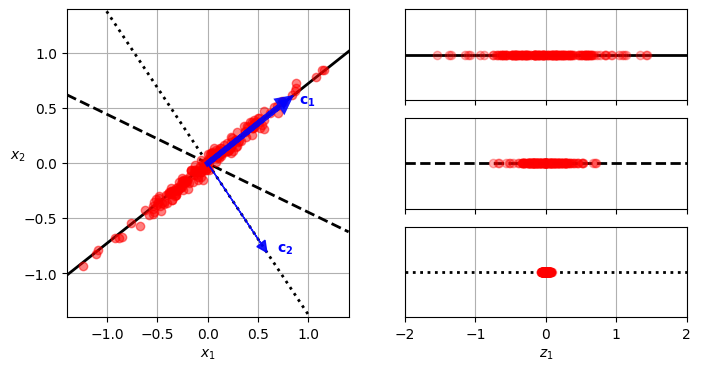

In [10]:
# extra
angle = np.pi / 5
stretch = 5
m = 200

np.random.seed(3)
X_line = np.random.randn(m, 2) / 10
X_line = X_line @ np.array([[stretch, 0], [0, 1]])  # stretch
X_line = X_line @ [[np.cos(angle), np.sin(angle)],
                   [np.sin(angle), np.cos(angle)]]  # rotate

u1 = np.array([np.cos(angle), np.sin(angle)])
u2 = np.array([np.cos(angle - 2 * np.pi / 6), np.sin(angle - 2 * np.pi / 6)])
u3 = np.array([np.cos(angle - np.pi / 2), np.sin(angle - np.pi / 2)])

X_proj1 = X_line @ u1.reshape(-1, 1)
X_proj2 = X_line @ u2.reshape(-1, 1)
X_proj3 = X_line @ u3.reshape(-1, 1)

plt.figure(figsize=(8, 4))
plt.subplot2grid((3, 2), (0, 0), rowspan=3)
plt.plot([-1.4, 1.4], [-1.4 * u1[1] / u1[0], 1.4 * u1[1] / u1[0]], "k-",
         linewidth=2)
plt.plot([-1.4, 1.4], [-1.4 * u2[1] / u2[0], 1.4 * u2[1] / u2[0]], "k--",
         linewidth=2)
plt.plot([-1.4, 1.4], [-1.4 * u3[1] / u3[0], 1.4 * u3[1] / u3[0]], "k:",
         linewidth=2)
plt.plot(X_line[:, 0], X_line[:, 1], "ro", alpha=0.5)
plt.arrow(0, 0, u1[0], u1[1], head_width=0.1, linewidth=4, alpha=0.9,
          length_includes_head=True, head_length=0.1, fc="b", ec="b", zorder=10)
plt.arrow(0, 0, u3[0], u3[1], head_width=0.1, linewidth=1, alpha=0.9,
          length_includes_head=True, head_length=0.1, fc="b", ec="b", zorder=10)
plt.text(u1[0] + 0.1, u1[1] - 0.05, r"$\mathbf{c_1}$", color="blue")
plt.text(u3[0] + 0.1, u3[1], r"$\mathbf{c_2}$", color="blue")
plt.xlabel("$x_1$")
plt.ylabel("$x_2$", rotation=0)
plt.axis([-1.4, 1.4, -1.4, 1.4])
plt.grid()

plt.subplot2grid((3, 2), (0, 1))
plt.plot([-2, 2], [0, 0], "k-", linewidth=2)
plt.plot(X_proj1[:, 0], np.zeros(m), "ro", alpha=0.3)
plt.gca().get_yaxis().set_ticks([])
plt.gca().get_xaxis().set_ticklabels([])
plt.axis([-2, 2, -1, 1])
plt.grid()

plt.subplot2grid((3, 2), (1, 1))
plt.plot([-2, 2], [0, 0], "k--", linewidth=2)
plt.plot(X_proj2[:, 0], np.zeros(m), "ro", alpha=0.3)
plt.gca().get_yaxis().set_ticks([])
plt.gca().get_xaxis().set_ticklabels([])
plt.axis([-2, 2, -1, 1])
plt.grid()

plt.subplot2grid((3, 2), (2, 1))
plt.plot([-2, 2], [0, 0], "k:", linewidth=2)
plt.plot(X_proj3[:, 0], np.zeros(m), "ro", alpha=0.3)
plt.gca().get_yaxis().set_ticks([])
plt.axis([-2, 2, -1, 1])
plt.xlabel("$z_1$")
plt.grid()
plt.show()


As you can see,
- the projection onto the solid line preserves the maximum variance (top),
- while the projection onto the dotted line preserves
very little variance (bottom),

- the projection onto the dashed line preserves an intermediate amount of variance
(middle).

So it seems reasonable to select the axis that preserves the maximum amount of variance, as it will most likely lose less
information than the other projections.


Another way to justify choosing the axis that maximizes the variance is that it is also the axis that minimizes the
mean squared distance between the original dataset and its projection onto that axis.

### 2.1 Principal Components

- PCA identifies the axis that accounts for the largest amount of variance in the trainign set.  

From last plot, it is the solid
line. It also finds a second axis, orthogonal to the first one, that accounts for the largest amount of the remaining variance.


In this 2D example there is no choice: it is the dotted line. If it were a higher-dimensional dataset, PCA would also find a
third axis, orthogonal to both previous axes, and a fourth, a fifth, and so on—as many axes as the number of dimensions
in the dataset.

In [11]:
import numpy as np
from scipy.spatial.transform import Rotation

m = 60
X= np.zeros((m,3))

np.random.seed(42)

# For uneven distribution
angles = (np.random.rand(m) ** 3 + 0.5) * 2 * np.pi

# oval
X[:,0] , X[:,1] = np.cos(angles) , np.sin(angles) * 0.5

# add more noise
X += 0.28 * np.random.randn(m,3)

X = Rotation.from_rotvec([np.pi / 29 , np.pi / 20, np.pi / 4]).apply(X)

# shift a bit
X += [0.2 , 0, 0.2]

X_centered = X - X.mean(axis = 0)
U , s, Vt = np.linalg.svd(X_centered)

c1 = Vt[0]
c2 = Vt[1]

The ith axis is called the ith principal component (PC) of the data.